# EXP-02A/B — Chunked Prompting, LVIS Aliases and Selective 2×2 Tiling (Sections 1–2)

**TPI Visual Scene Understanding — UTN Artificial Intelligence, Spring 2026 — Group 2**

**Problem.** EXP-01 (OWLv2 Base, the 120 raw names in one prompt) reached CAL Box F1 = 0.6576 but only **0.516 box recall on small objects**, and 71.06% of the 1,790 GT instances have `area_ratio < 0.01` (median 0.00289: rings, watches, doorknobs, handles, wall sockets, forks, knives, cell phones…). Perception is 40% of the `PipelineScore`, and small objects make up most of its false negatives.

**Hypotheses.**
- **EXP-02A:** splitting the vocabulary into 5 semantic blocks of 24 classes (*Chunked Prompting*) and adding visual aliases for archaic/ambiguous LVIS names (`LVIS_PROMPT_ALIASES`, remapped to the official `category_id`) raises recall without hurting precision.
- **EXP-02B:** an additional pass over 2×2 overlapping tiles (25% overlap), restricted to small/medium categories, with boxes projected back to `[0, W] × [0, H]` and truncation artifacts on inner tile borders removed, raises recall on small objects (`area_ratio < 0.0035`).

**Controlled design.**
- Both ablations run on `CAL` (80 images, 1,231 GT instances). Each one changes one variable at a time against its own control arm.
- Every arm gets its own CAL-optimal score threshold, so arms are compared at their best operating point, not at a threshold inherited from another arm.
- `VAL` is never consulted here; the held-out comparison belongs to T4 (Section 3).

**Evaluation.**
- Box-only LVIS federated matching (IoU ≥ 0.5), the exact rule of `lvis_evaluator.evaluate_federated`, computed per image (`box_match_details`).
- *Statistically significant* means the 95% CI of a paired image-level bootstrap (1,000 resamples, `SEED = 42`) excludes 0.

**Compute.**
- The detections were produced on a **Kaggle Tesla T4** by `scripts/run_exp02_inference.py` (OWLv2 Base and OWLv2 Large) and cached in `artifacts/cache_exp02/`.
- This notebook only reads those caches, so it runs on CPU in under a minute. `annotations.json` is used **only** for evaluation; the runner never opens it.

In [1]:
import json, platform, sys
from collections import Counter, defaultdict
from pathlib import Path

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

from src import config_and_seeds as cfg
from src import lvis_evaluator as ev
from src import pipeline as pl
from src import perception_detectors as pdet

cfg.set_global_seeds(cfg.SEED)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
PATHS = cfg.get_dataset_paths()
ANNOTATIONS = json.loads(PATHS.annotations.read_text(encoding="utf-8"))  # evaluation only, never inference
GT = ev.load_gt(ANNOTATIONS)
SPLIT = cfg.load_split()
CAL_KEYS = [f"tpi_{i:04d}" for i in SPLIT["cal"]]
AREA_RATIO = {k: [float(m.sum()) / (g["height"] * g["width"]) for m in g["masks"]] for k, g in GT.items()}

CACHE_DIR = REPO / "artifacts" / "cache_exp02"
BACKBONES = ("base", "large")
DETS, META = {}, {}
for bb in BACKBONES:
    for v in pdet.VARIANTS:
        DETS[bb, v], META[bb, v] = pl.load_detection_cache(CACHE_DIR / bb / f"detections_{v}.json.gz")
SIZES = META["base", "single_raw"]["image_sizes"]  # [W, H] per image, recorded by the runner
EXP01 = pl.load_detection_cache(REPO / "artifacts" / "cache_exp01" / "detections.json")[0]
TRACE = {bb: [json.loads(l) for l in (CACHE_DIR / bb / "trace_detection.jsonl").read_text().splitlines() if l.strip()]
         for bb in BACKBONES}

print(f"Python {platform.python_version()} | SEED={cfg.SEED} | CAL images: {len(CAL_KEYS)} | "
      f"CAL GT instances: {sum(len(GT[k]['boxes']) for k in CAL_KEYS)}")
display(pd.DataFrame([{"backbone": bb, "model": m["model"], "device": m["device"], "gpu": m["gpu"], "torch": m["torch"],
                       "created_at": m["created_at"], "text queries": m["n_queries"],
                       "images": len(DETS[bb, "single_raw"]), "tile overlap": m["tile_overlap"],
                       "score floor": m["min_score"], "truncation-filtered in cache": m["truncation_filtered"]}
                      for bb in BACKBONES for m in [META[bb, "single_raw"]]]))

Python 3.12.12 | SEED=42 | CAL images: 80 | CAL GT instances: 1231


,backbone,model,device,gpu,torch,created_at,text queries,images,tile overlap,score floor,truncation-filtered in cache
0,base,google/owlv2-base-patch16-ensemble,cuda,Tesla T4,2.11.0+cu128,2026-10-29T11:11:24+00:00,183,180,0.25,0.05,False
1,large,google/owlv2-large-patch14-ensemble,cuda,Tesla T4,2.11.0+cu128,2026-10-29T11:20:47+00:00,183,180,0.25,0.05,False


In [2]:
# Shared evaluation helpers: box-only LVIS federated matching (IoU >= 0.5), per image, so that every comparison can be
# bootstrapped paired by image. Size buckets use the rasterized GT mask area_ratio (same definition as EXP-01).
THRESHOLDS = np.round(np.arange(0.05, 0.601, 0.025), 3)
TILE_THRESHOLDS = np.round(np.arange(0.15, 0.501, 0.025), 3)
BUCKETS = ("small", "medium", "large")
GT_BUCKET = {k: [cfg.size_from_area_ratio(a) for a in AREA_RATIO[k]] for k in CAL_KEYS}
GROUPS = pdet.sibling_groups(cfg.CATEGORIES)
METRICS = ["P", "R", "F1", "R_small", "R_medium", "R_large"]


def as_preds(dets):
    return [{"category_id": d.category_id, "confidence": d.score, "bbox": list(d.bbox)} for d in dets]


def is_global(d):
    return pdet.view_index(d.source) is None


def global_only(dets_by_key):
    return {k: [d for d in dets_by_key[k] if is_global(d)] for k in CAL_KEYS}


def at_threshold(dets_by_key, thr):
    return {k: [d for d in dets_by_key[k] if d.score >= thr] for k in CAL_KEYS}


def per_image_counts(dets_by_key):
    """[n_images, 9]: tp, fp, fn, then (matched, total) GT instances for small / medium / large."""
    per = ev.box_match_details({k: as_preds(dets_by_key[k]) for k in CAL_KEYS}, GT)
    rows = []
    for k in CAL_KEYS:
        row = [per[k]["tp"], per[k]["fp"], per[k]["fn"]]
        for b in BUCKETS:
            flags = [hit for hit, s in zip(per[k]["gt_matched"], GT_BUCKET[k]) if s == b]
            row += [sum(flags), len(flags)]
        rows.append(row)
    return np.array(rows, dtype=float)


def metrics_from_sums(s):
    """Vectorised over leading axes: s[..., 9] summed counts -> dict of metric arrays."""
    tp, fp, fn = s[..., 0], s[..., 1], s[..., 2]
    p, r = tp / np.maximum(tp + fp, 1), tp / np.maximum(tp + fn, 1)
    out = {"P": p, "R": r, "F1": np.where(p + r > 0, 2 * p * r / np.maximum(p + r, 1e-12), 0.0)}
    for i, b in enumerate(BUCKETS):
        out[f"R_{b}"] = s[..., 3 + 2 * i] / np.maximum(s[..., 4 + 2 * i], 1)
    return out


def summarize(dets_by_key, name, **extra):
    counts = per_image_counts(dets_by_key)
    m = metrics_from_sums(counts.sum(axis=0))
    return {"arm": name, **extra, **{k: float(m[k]) for k in METRICS},
            "det/img": float(np.mean([len(dets_by_key[k]) for k in CAL_KEYS]))}


def sweep(make, thresholds):
    return pd.DataFrame([{"threshold": float(t), **summarize(make(t), str(t))} for t in thresholds])


def bootstrap_delta(counts_a, counts_b, n_boot=1000, seed=cfg.SEED):
    """Paired image-level bootstrap of (b - a) per metric: point estimate, 95% percentile CI, P(delta <= 0)."""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(counts_a), size=(n_boot, len(counts_a)))
    ma, mb = metrics_from_sums(counts_a[idx].sum(axis=1)), metrics_from_sums(counts_b[idx].sum(axis=1))
    pa, pb = metrics_from_sums(counts_a.sum(axis=0)), metrics_from_sums(counts_b.sum(axis=0))
    rows = {}
    for k in METRICS:
        d = mb[k] - ma[k]
        rows[k] = {"delta": float(pb[k] - pa[k]), "ci_low": float(np.percentile(d, 2.5)),
                   "ci_high": float(np.percentile(d, 97.5)), "p(delta<=0)": float(np.mean(d <= 0))}
    return rows


n_bucket = Counter(b for k in CAL_KEYS for b in GT_BUCKET[k])
print("CAL GT instances by size bucket:", dict(n_bucket),
      f"| small share = {n_bucket['small'] / sum(n_bucket.values()):.1%}")

CAL GT instances by size bucket: {'medium': 432, 'small': 639, 'large': 160} | small share = 51.9%


**Analysis — provenance and evaluation protocol.**

- **Provenance.**
  - Both backbones ran on the same Tesla T4 (torch 2.11.0+cu128), over all 180 images (120 dev + 60 test, so T4 can reuse the cache).
  - The same 183 text queries were used for both: 120 official names + 63 aliases.
  - The score floor is 0.05, as in EXP-01.
  - Tile detections were cached **before** truncation filtering (`truncation-filtered in cache = False`), so the inner-edge filter, the tiled-category subset and the tile threshold can all be ablated here without touching the GPU again.
- **Where the errors are.**
  - CAL contains 639 small, 432 medium and 160 large GT instances: **51.9% of the instances to be found are small**.
  - At EXP-01's small recall (0.516), this bucket alone accounts for ~309 missed boxes. That is the target of this notebook.
- **Why box-only.**
  - The score threshold decides *which* objects exist. SAM2 only decides their shape (EXP-03), so detection choices are scored on boxes and segmentation stays out of the decision, as in EXP-01.
  - `per_image_counts` stores TP/FP/FN and matched/total GT per size bucket for each image. Bootstrap resamples images (the unit of variation) and recomputes F1 from the summed counts, exactly as the official metric aggregates them.

## Section 1 — EXP-02A: Single Prompt (120 raw classes) vs. Chunked Prompting (5 × 24) + LVIS Aliases

**A mechanistic point fixes how this ablation should be read.**
- OWLv2's class head scores each text query **independently**: a dot product between the box embedding and the normalised query embedding, with a shift/scale that depends only on the image (`modeling_owlv2.py`). Adding or removing queries never changes another query's score.
- So the "attention dilution" argument behind chunked prompting does not apply to OWLv2. It applies to text encoders that read all classes in one sequence, such as Grounding DINO / MM-GDINO and their 256-token limit (T4).
- For OWLv2, chunking changes exactly one thing: the label of each box is the argmax **within each block**, so a box can carry up to 5 labels (one per block) instead of a single one.
- Because scores do not interact, **one forward pass over the 183 alias queries is mathematically identical to five chunked passes**. The runner therefore extracts a full 2×2 factorial from a single image encoding:

| variant | blocks | queries per category |
|---|---|---|
| `single_raw` (= EXP-01) | 1 × 120 | official name |
| `single_alias` | 1 × 120 | max over official name + aliases |
| `chunked_raw` | 5 × 24 | official name |
| `chunked_alias` (master-plan treatment) | 5 × 24 | max over official name + aliases |

This separates the effect of chunking from the effect of aliases, which a plain "single block vs. 5 blocks + aliases" comparison would confound.

In [3]:
BLOCKS = pdet.build_blocks(cfg.CATEGORIES)
QUERY_TABLE = pdet.build_query_table(cfg.LVIS_PROMPT_ALIASES)
display(pd.DataFrame([{"block": name, "classes": len(ids), "members": ", ".join(cfg.CATEGORIES[c] for c in ids)}
                      for name, ids in BLOCKS.items()]))
alias_rows = [{"id": cid, "official name": e["name"], "visual aliases (remapped to the official id)": ", ".join(e["prompts"][1:])}
              for cid, e in cfg.LVIS_PROMPT_ALIASES.items() if len(e["prompts"]) > 1]
print(f"{len(alias_rows)} of 120 categories carry aliases -> {len(QUERY_TABLE.prompts)} text queries "
      f"(template {pdet.PROMPT_TEMPLATE!r}); every query maps to exactly one category_id")
display(pd.DataFrame(alias_rows))
display(pd.DataFrame([{"sibling group": " / ".join(cfg.CATEGORIES[c] for c in sorted(g)),
                       "block": next(n for n, ids in BLOCKS.items() if g <= set(ids))} for g in GROUPS]))

,block,classes,members
0,apparel,24,"person, jacket, shirt, jersey, dress, trousers, jean, short pants, sock, shoe, boot, ski boot, glove, baseball glove, belt, necktie, hat..."
1,accessories_electronics,24,"necklace, earring, bracelet, ring, watch, clock, spectacles, sunglasses, goggles, cell phone, laptop, computer keyboard, computer mouse,..."
2,kitchen_tableware,24,"pizza, banana, broccoli, bottle, drinking glass, cup, bowl, plate, fork, knife, napkin, tablecloth, vase, flower arrangement, flowerpot,..."
3,home_street_fixtures,24,"sofa, chair, pillow, blanket, bed, curtain, toilet, wall socket, vent, trash can, bench, awning, banner, flag, signboard, street sign, t..."
4,vehicles_animals_sports,24,"car, bus, train, airplane, boat, motorcycle, bicycle, wheel, horse, dog, cat, bird, elephant, giraffe, zebra, cow, tennis racket, baseba..."


45 of 120 categories carry aliases -> 183 text queries (template 'a photo of a {}'); every query maps to exactly one category_id


,id,official name,visual aliases (remapped to the official id)
0,1,sofa,couch
1,6,signboard,"shop sign, billboard"
2,11,handle,"door handle, drawer handle"
3,18,trousers,pants
4,19,trash can,"garbage can, trash bin"
5,22,bicycle,bike
6,25,cell phone,"mobile phone, smartphone"
7,33,computer keyboard,keyboard
8,35,jean,"jeans, denim pants"
9,36,short pants,shorts


,sibling group,block
0,clock / watch,accessories_electronics
1,trousers / jean / short pants,apparel
2,shoe / ski boot / boot,apparel
3,handle / doorknob / knob,kitchen_tableware
4,sunglasses / spectacles / goggles,accessories_electronics


**Analysis — prompt design and disambiguation rules.**

- **Blocks.**
  - Five semantic blocks of exactly 24 classes: apparel, accessories/electronics, kitchen/tableware, home/street fixtures, vehicles/animals/sports.
  - They form an exact partition of ids 1–120 (unit-tested).
  - The grouping follows visual context, so that classes that co-occur and compete for the same boxes are arbitrated against each other.
- **Sibling rule by construction.**
  - Each sibling group (`clock`/`watch`, `trousers`/`jean`/`short pants`, `shoe`/`boot`/`ski boot`, `handle`/`doorknob`/`knob`, `spectacles`/`sunglasses`/`goggles`) lives **inside one block**.
  - Since the label is the per-block argmax, two siblings can never both label the same predicted box. The per-block argmax *is* the disambiguation.
  - A cross-class NMS restricted to sibling groups (`suppress_siblings`, IoU ≥ 0.7) is kept as an explicit second rule for overlapping boxes and measured below.
- **Aliases.**
  - 45 categories carry visual synonyms (183 queries in total). Each alias is remapped to its official `category_id` by max-pooling its scores.
  - Building this table exposed real ambiguities in the inherited alias list, which are now fixed and enforced by a fail-fast invariant (**one prompt → exactly one category**):
    - `"door handle"` was listed under both `doorknob` and `handle`.
    - Bare `glasses` (vs. drinking glass/sunglasses), `t-shirt` (jersey vs. shirt), `watch strap` (strap vs. watch), `mouse` (animal), `cap`, `sign` and `post` were too generic and could remap boxes to the wrong class.
  - An alias that is a synonym of *another* category would silently convert true positives of one class into false positives of another.

In [4]:
# Regression: the single-block raw variant of the alias-union pass (T4 GPU) must reproduce the EXP-01 cache (CPU).
ref, new = {k: EXP01[k] for k in CAL_KEYS}, global_only(DETS["base", "single_raw"])
same_count = sum(len(ref[k]) == len(new[k]) for k in CAL_KEYS)
key_of = lambda d: (d.category_id, tuple(round(v, 1) for v in d.bbox))
diffs, unmatched = [], 0
for k in CAL_KEYS:
    by_key = {key_of(d): d.score for d in new[k]}
    for d in ref[k]:
        if key_of(d) in by_key:
            diffs.append(abs(by_key[key_of(d)] - d.score))
        else:
            unmatched += 1
print(f"images with identical detection counts: {same_count}/{len(CAL_KEYS)} | EXP-01 detections without a "
      f"counterpart: {unmatched} | max |score diff| = {max(diffs):.1e} (cache rounding 1e-4 + GPU/CPU float)")
display(pd.DataFrame([summarize(at_threshold(ref, 0.175), "EXP-01 cache (CPU, 120-query pass)"),
                      summarize(at_threshold(new, 0.175), "EXP-02 base single_raw, global view (T4 GPU, 183-query pass)")]
                     ).round(4))

images with identical detection counts: 80/80 | EXP-01 detections without a counterpart: 37 | max |score diff| = 7.0e-04 (cache rounding 1e-4 + GPU/CPU float)


,arm,P,R,F1,R_small,R_medium,R_large,det/img
0,"EXP-01 cache (CPU, 120-query pass)",0.6883,0.6296,0.6576,0.5164,0.7384,0.7875,33.125
1,"EXP-02 base single_raw, global view (T4 GPU, 183-query pass)",0.6883,0.6296,0.6576,0.5164,0.7384,0.7875,33.125


**Analysis — regression check against EXP-01.**

- **The control arm is the baseline.** `single_raw` from the 183-query alias-union pass on the T4 GPU reproduces the EXP-01 cache (120-query pass on CPU) **exactly at the metric level**:
  - same P / R / F1 (0.6883 / 0.6296 / 0.6576);
  - same recall in every size bucket;
  - same 33.1 detections per image;
  - identical detection counts in 80/80 images.
- **Residual differences are numerical, not behavioural.**
  - The maximum score difference is 7·10⁻⁴: GPU vs. CPU float arithmetic plus the 4-decimal rounding of the compressed cache.
  - The 37 detections "without a counterpart" are an artifact of this check's own key, which rounds coordinates to 0.1 px. A coordinate that moved by 10⁻⁴ across a rounding boundary changes the key. Counts and all metrics are identical, so no detection actually appeared or disappeared.
- **Consequence.** Adding 63 alias queries does not perturb the official-name scores (as the architecture predicts), and the GPU run is a faithful superset of EXP-01. Every delta below can be attributed to the manipulated variable and not to the environment.

,arm,threshold,P,R,F1,R_small,R_medium,R_large,R@0.05 (ceiling),det/img
0,base / single_raw,0.175,0.6883,0.6296,0.6576,0.5164,0.7384,0.7875,0.7669,33.1250
1,base / single_alias,0.175,0.6762,0.6328,0.6538,0.5196,0.7431,0.7875,0.7636,34.6375
2,base / chunked_raw,0.175,0.6850,0.6361,0.6596,0.5211,0.7454,0.8000,0.7782,34.0500
3,base / chunked_alias,0.175,0.6704,0.6377,0.6536,0.5227,0.7500,0.7938,0.7758,35.7500
4,large / single_raw,0.175,0.6719,0.5857,0.6259,0.4757,0.6991,0.7188,0.7571,27.4000
5,large / single_alias,0.175,0.6651,0.5890,0.6247,0.4789,0.7037,0.7188,0.7539,28.9500
6,large / chunked_raw,0.175,0.6673,0.5898,0.6261,0.4773,0.7014,0.7375,0.7701,27.8375
7,large / chunked_alias,0.175,0.6594,0.5930,0.6245,0.4820,0.7060,0.7312,0.7660,29.5125


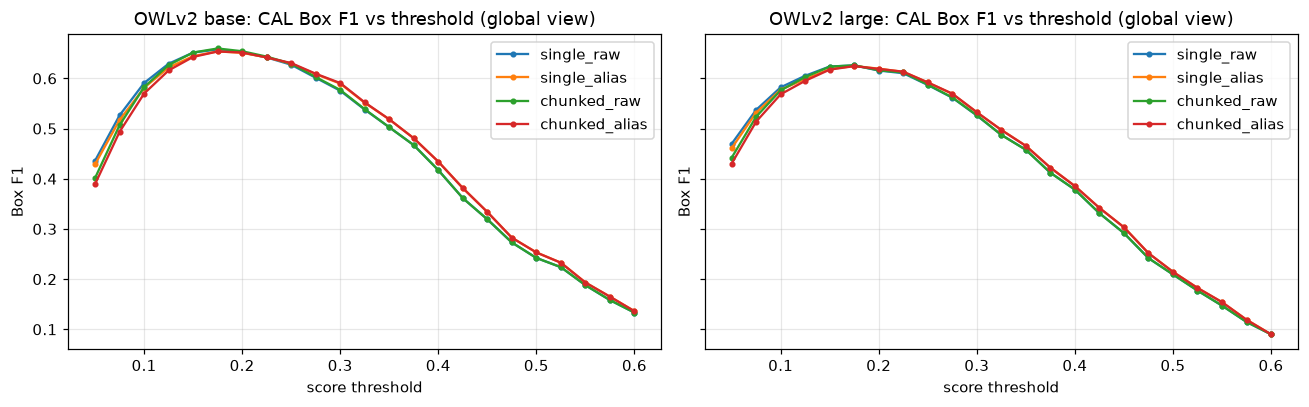

In [5]:
rows, CURVES = [], {}
for bb in BACKBONES:
    for v in pdet.VARIANTS:
        g = global_only(DETS[bb, v])
        sw = sweep(lambda t: at_threshold(g, t), THRESHOLDS)
        CURVES[bb, v] = sw
        best = sw.loc[sw["F1"].idxmax()]
        rows.append({**summarize(at_threshold(g, best["threshold"]), f"{bb} / {v}"), "backbone": bb, "variant": v,
                     "threshold": best["threshold"], "R@0.05 (ceiling)": sw.iloc[0]["R"]})
EXP02A = pd.DataFrame(rows)
BEST_T = {(r.backbone, r.variant): r.threshold for r in EXP02A.itertuples()}
display(EXP02A[["arm", "threshold", "P", "R", "F1", "R_small", "R_medium", "R_large", "R@0.05 (ceiling)", "det/img"]]
        .round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, bb in zip(axes, BACKBONES):
    for v in pdet.VARIANTS:
        ax.plot(CURVES[bb, v]["threshold"], CURVES[bb, v]["F1"], marker=".", label=v)
    ax.set(title=f"OWLv2 {bb}: CAL Box F1 vs threshold (global view)", xlabel="score threshold", ylabel="Box F1")
    ax.legend()
plt.tight_layout()
plt.show()

**Analysis — the 2×2 factorial (global view only).**

- **Optimum and curves.**
  - All 8 arms share the same CAL-optimal threshold (0.175) and an almost identical F1 curve; the curves overlap within ±0.01 at every threshold.
  - The prompting variable barely moves the operating point.
- **Chunking (`chunked_raw` vs `single_raw`).**
  - Best global arm: F1 0.6596 vs. 0.6576 (+0.002). Recall +0.65 pp, precision −0.3 pp.
  - The recall ceiling at the 0.05 floor rises from 0.767 to 0.778. This is the one-label-per-block effect: a box whose best overall class was wrong can now also carry the right class from another block.
- **Aliases (`single_alias` vs `single_raw`).** Recall +0.3 pp but precision −1.2 pp (F1 −0.004). Aliases add 1.5 detections per image, and most of them do not match a GT box.
- **Both combined (`chunked_alias`, the master-plan treatment).**
  - Highest raw recall (0.6377) and highest small recall of the global arms (0.523), but also the lowest precision (0.670).
  - Net F1 0.6536, *below* the baseline.
- **OWLv2 Large is worse than Base in every arm.**
  - F1 ≈ 0.625 vs. ≈ 0.656, recall −4 to −5 pp, small recall 0.48 vs. 0.52.
  - Its threshold sweep covers 0.05–0.60 and peaks at the same 0.175, so this is not a mis-chosen operating point.
  - The master plan assumes Large is the stronger detector; this result directly affects T4 (see conclusions).

In [6]:
COUNTS_A = {key: per_image_counts(at_threshold(global_only(DETS[key]), t)) for key, t in BEST_T.items()}
rows = []
for bb in BACKBONES:
    for v in pdet.VARIANTS[1:]:
        boot = bootstrap_delta(COUNTS_A[bb, "single_raw"], COUNTS_A[bb, v])
        rows += [{"comparison": f"{bb}: {v} - single_raw", "metric": m, **boot[m]} for m in ("F1", "P", "R", "R_small")]
boot = bootstrap_delta(COUNTS_A["base", "single_raw"], COUNTS_A["large", "single_raw"])
rows += [{"comparison": "single_raw: large - base", "metric": m, **boot[m]} for m in ("F1", "P", "R", "R_small")]
BOOT_A = pd.DataFrame(rows)
BOOT_A["significant (95% CI excludes 0)"] = (BOOT_A["ci_low"] > 0) | (BOOT_A["ci_high"] < 0)
display(BOOT_A.round(4))

,comparison,metric,delta,ci_low,ci_high,p(delta<=0),significant (95% CI excludes 0)
0,base: single_alias - single_raw,F1,-0.0038,-0.0118,0.0056,0.821,False
1,base: single_alias - single_raw,P,-0.0121,-0.0233,-0.0023,0.996,True
2,base: single_alias - single_raw,R,0.0032,-0.0052,0.0142,0.355,False
3,base: single_alias - single_raw,R_small,0.0031,-0.0034,0.0103,0.290,False
4,base: chunked_raw - single_raw,F1,0.0020,-0.0021,0.0071,0.185,False
5,base: chunked_raw - single_raw,P,-0.0032,-0.0079,0.0015,0.915,False
6,base: chunked_raw - single_raw,R,0.0065,0.0017,0.0134,0.002,True
7,base: chunked_raw - single_raw,R_small,0.0047,0.0000,0.0101,0.046,False
8,base: chunked_alias - single_raw,F1,-0.0040,-0.0130,0.0056,0.793,False
9,base: chunked_alias - single_raw,P,-0.0179,-0.0294,-0.0072,1.000,True


**Analysis — paired bootstrap of the EXP-02A effects (95% CI over CAL images).**

- **No prompting variant changes Box F1 significantly.**
  - Every F1 delta has a CI that straddles 0, with point estimates between −0.004 and +0.002.
- **Chunking buys recall at no significant precision cost.**
  - Base: R +0.65 pp, CI [+0.17, +1.34], p = 0.002. Precision −0.32 pp, CI [−0.79, +0.15], not significant.
  - Large replicates it: R +0.41 pp, CI [+0.08, +0.81]. The effect is small but real and consistent with the mechanism (extra labels per box).
- **Aliases significantly *hurt* precision and do not significantly help recall.**
  - Base `single_alias`: P −1.21 pp, CI [−2.33, −0.23]. Base `chunked_alias`: P −1.79 pp, CI [−2.94, −0.72], p(Δ ≤ 0) = 1.00.
  - Large shows the same pattern.
  - Small-recall gains from aliases (+0.3 to +0.6 pp) are not significant.
- **Large vs. Base (`single_raw`).**
  - F1 −0.032, CI [−0.056, −0.008]: significant. Recall −4.4 pp: significant. Small recall −4.1 pp, with the CI touching 0.
- **Verdict on EXP-02A.**
  - The "5 blocks + aliases" hypothesis is **refuted for OWLv2 as a Box-F1 lever**. Chunking is a mild, significant recall gain at no inference cost; aliases are a net precision loss.
  - The architecture predicted this outcome before any data was seen. OWLv2's CLIP text tower embeds each query independently, so there was never any attention saturation to remove.

In [7]:
def recall_by_category(dets_by_key):
    per = ev.box_match_details({k: as_preds(dets_by_key[k]) for k in CAL_KEYS}, GT)
    hits = defaultdict(lambda: [0, 0])
    for k in CAL_KEYS:
        for cid, hit in zip(GT[k]["categories"], per[k]["gt_matched"]):
            hits[cid][0] += hit
            hits[cid][1] += 1
    return hits

def n_pred_by_category(dets_by_key):
    return Counter(d.category_id for k in CAL_KEYS for d in dets_by_key[k])

raw = at_threshold(global_only(DETS["base", "single_raw"]), BEST_T["base", "single_raw"])
alias = at_threshold(global_only(DETS["base", "single_alias"]), BEST_T["base", "single_alias"])
h_raw, h_alias = recall_by_category(raw), recall_by_category(alias)
p_raw, p_alias = n_pred_by_category(raw), n_pred_by_category(alias)
rows = [{"category": e["name"], "aliases": ", ".join(e["prompts"][1:]), "CAL GT": h_raw[cid][1],
         "recall raw": h_raw[cid][0] / h_raw[cid][1], "recall alias": h_alias[cid][0] / h_alias[cid][1],
         "predictions raw": p_raw[cid], "predictions alias": p_alias[cid]}
        for cid, e in cfg.LVIS_PROMPT_ALIASES.items() if len(e["prompts"]) > 1 and h_raw[cid][1] > 0]
ALIAS_CAT = pd.DataFrame(rows)
ALIAS_CAT["delta recall"] = ALIAS_CAT["recall alias"] - ALIAS_CAT["recall raw"]
display(ALIAS_CAT.sort_values(["delta recall", "CAL GT"], ascending=[False, False]).round(3))
tot = ALIAS_CAT[["CAL GT", "predictions raw", "predictions alias"]].sum()
gained = int(round((ALIAS_CAT["delta recall"] * ALIAS_CAT["CAL GT"]).sum()))
print(f"aliased categories present in CAL: {len(ALIAS_CAT)} | GT instances: {int(tot['CAL GT'])} | net matched "
      f"instances gained: {gained:+d} | predictions {int(tot['predictions raw'])} -> {int(tot['predictions alias'])} "
      f"(base, single block, each at its CAL-optimal threshold)")

,category,aliases,CAL GT,recall raw,recall alias,predictions raw,predictions alias,delta recall
24,jersey,sports jersey,21,0.667,0.905,24,33,0.238
22,baseball cap,sports cap,19,0.737,0.789,31,34,0.053
36,strap,"shoulder strap, bag strap",19,0.053,0.105,27,33,0.053
2,handle,"door handle, drawer handle",20,0.400,0.450,48,92,0.050
5,bicycle,bike,27,0.593,0.593,45,46,0.000
37,knob,"cabinet knob, control knob",23,0.739,0.739,61,62,0.000
39,awning,canopy,20,0.350,0.350,44,44,0.000
10,flower arrangement,"bouquet, flowers in vase",15,0.600,0.600,14,19,0.000
31,ski boot,ski boots,15,0.800,0.800,18,20,0.000
42,flowerpot,"plant pot, flower pot",15,0.667,0.667,32,39,0.000


aliased categories present in CAL: 45 | GT instances: 417 | net matched instances gained: +6 | predictions 1082 -> 1229 (base, single block, each at its CAL-optimal threshold)


**Analysis — where aliases help and where they hurt (Base, single block, each arm at its CAL optimum).**

- **Net effect.**
  - Over the 45 aliased categories present in CAL (417 GT instances), aliases gain a net **+6 matched instances**, while predictions in those categories grow **+13.6%** (1,082 → 1,229).
  - Each extra true positive costs roughly 24 extra predictions, which is the precision loss measured above.
- **Real wins come from fixing grounding, not archaisms.**
  - `jersey`: 0.667 → 0.905 (+5 of 21 instances) with `sports jersey`.
  - `baseball cap`, `strap` and `handle`: +1 each, matching the EXP-01 note that `strap` grounds poorly with its raw name.
- **The textbook archaisms have no headroom on CAL.**
  - `fireplug`, `spectacles` and `television set` are already at recall 1.0 with their raw names: OWLv2's CLIP text encoder knows them.
  - `fireplug` has only 2 CAL instances, so the motivating example cannot move the metric.
- **A new sibling-like confusion appears.**
  - `computer monitor` falls 0.8 → 0.6 (−2): the `tv`/`television` aliases of `television set` now win the single-block argmax on monitor boxes.
  - This is the failure mode the one-prompt-one-category invariant cannot catch: two *different* aliases that describe the *same* visual concept. The pair (`computer monitor`, `television set`) is a candidate sibling group.
- **Pure false-positive generators.**
  - `tag` triples its predictions (9 → 27) with no recall change; `handle` almost doubles them (48 → 92) for a single extra match.
  - These classes are exactly the "background-prone" categories the master plan flags for stricter thresholds.
- **Decision.**
  - Aliases are **off by default** for OWLv2.
  - They remain available (`detect_variants` always computes them), and they may matter more for MM-GDINO in T4, where the BERT text encoder is less robust to archaic names than CLIP.

In [8]:
def sibling_confusions(dets_by_key):
    """Missed GT instances of a sibling class X that a look-alike sibling Y localises (IoU >= 0.5)."""
    per = ev.box_match_details({k: as_preds(dets_by_key[k]) for k in CAL_KEYS}, GT)
    n_gt = n_conf = 0
    for k in CAL_KEYS:
        for cid, box, hit in zip(GT[k]["categories"], GT[k]["boxes"], per[k]["gt_matched"]):
            group = next((g for g in GROUPS if cid in g), None)
            if group is None:
                continue
            n_gt += 1
            n_conf += (not hit) and any(d.category_id in group and d.category_id != cid
                                        and ev.box_iou(list(d.bbox), box) >= ev.IOU_THRESHOLD for d in dets_by_key[k])
    return n_gt, n_conf

rows = []
for bb in BACKBONES:
    for v in pdet.VARIANTS:
        g = global_only(DETS[bb, v])
        op = at_threshold(g, BEST_T[bb, v])
        sup_op = {k: pdet.suppress_siblings(op[k], GROUPS) for k in CAL_KEYS}
        sup_floor = sum(len(g[k]) - len(pdet.suppress_siblings(g[k], GROUPS)) for k in CAL_KEYS)
        n_gt, n_conf = sibling_confusions(op)
        rows.append({"arm": f"{bb} / {v}", "suppressed @ operating thr": sum(len(op[k]) - len(sup_op[k]) for k in CAL_KEYS),
                     "suppressed @ 0.05 floor": sup_floor, "F1 without rule": summarize(op, "")["F1"],
                     "F1 with rule": summarize(sup_op, "")["F1"], "sibling GT in CAL": n_gt,
                     "missed GT localised by a sibling label": n_conf})
display(pd.DataFrame(rows).round(4))

,arm,suppressed @ operating thr,suppressed @ 0.05 floor,F1 without rule,F1 with rule,sibling GT in CAL,missed GT localised by a sibling label
0,base / single_raw,0,9,0.6576,0.6576,155,7
1,base / single_alias,0,17,0.6538,0.6538,155,7
2,base / chunked_raw,0,9,0.6596,0.6596,155,7
3,base / chunked_alias,0,18,0.6536,0.6536,155,7
4,large / single_raw,0,11,0.6259,0.6259,155,10
5,large / single_alias,0,14,0.6247,0.6247,155,10
6,large / chunked_raw,0,12,0.6261,0.6261,155,10
7,large / chunked_alias,0,15,0.6245,0.6245,155,10


**Analysis — explicit sibling suppression.**

- **The explicit rule is a no-op at every operating point.**
  - `suppress_siblings` (IoU ≥ 0.7) removes **0 detections** at the CAL-optimal threshold in all 8 arms, so F1 is unchanged.
  - It only fires below the operating point (9–18 suppressions at the 0.05 floor).
- **Why.** Siblings share a block, so the per-block argmax already prevents two siblings from labelling the same predicted box. Two *different* boxes with sibling labels overlapping at IoU ≥ 0.7 only occur among low-scoring candidates. The disambiguation work is done by the block design, not by post-hoc NMS.
- **The real residual error is a wrong winner, not a duplicate.**
  - Of the 155 sibling-class GT instances in CAL, 7 (Base) / 10 (Large) are missed while a sibling label correctly localises them (IoU ≥ 0.5): a `boot` called `shoe`, a `jean` called `trousers`.
  - Suppression cannot recover those. It would need re-ranking with a different signal (e.g. a size prior for `watch` vs. `clock`, or context). At 4.5% of sibling instances it is a minor error source compared with small-object misses.
- **Decision.** The rule stays in the code (it is free and guards T4's multi-detector fusion, where siblings from *different* detectors can overlap), but it is not a lever for EXP-02.

In [9]:
WIN = EXP02A.loc[EXP02A["F1"].idxmax()]
WIN_KEY, WIN_T = (WIN["backbone"], WIN["variant"]), float(WIN["threshold"])
print(f"EXP-02A selection rule (max CAL Box F1 over the 8 global arms): backbone={WIN_KEY[0]}, variant={WIN_KEY[1]}, "
      f"threshold={WIN_T}, F1={WIN['F1']:.4f}, R_small={WIN['R_small']:.4f}")

EXP-02A selection rule (max CAL Box F1 over the 8 global arms): backbone=base, variant=chunked_raw, threshold=0.175, F1=0.6596, R_small=0.5211


**Decision — configuration carried into EXP-02B.**

- The pre-declared rule (maximum CAL Box F1 over the 8 global arms) selects **OWLv2 Base + `chunked_raw` at threshold 0.175** (F1 0.6596).
- Its F1 advantage over `single_raw` (+0.002) is not significant, so the choice is justified on two other grounds:
  1. It is the only prompting change with a **significant recall gain** and no significant precision cost.
  2. With OWLv2 it is **free**: same forward pass, same latency.
- Aliases are dropped from the default configuration (significant precision loss). Large is not carried forward (significantly worse).
- EXP-02B therefore isolates tiling on top of `base / chunked_raw`. Section 2.5 checks that the tiling effect does not depend on this choice.

## Section 2 — EXP-02B: Full Image vs. Full Image + Selective 2×2 Tiling

**Mechanism.**
- OWLv2 resizes every input to a fixed square (960 px for Base).
- A 640×480 photo is upsampled 1.5× and each 16-px patch covers ~10.7 px of the original. A ring or a watch of 10–15 px therefore spans one or two patches: below what the box head can localise.
- Cropping a 366×275 tile and feeding it to the same model upsamples it 2.6×, so each patch covers ~6.1 px: **1.75× more resolution per axis** on the same object.

**Arms.**
- Each arm adds one ingredient to the previous one, and its free thresholds are re-tuned on CAL:

| arm | change |
|---|---|
| B0 | full image only (EXP-02A winner) |
| B1 | + 4 tiles, one shared threshold, no truncation filter (the naive implementation) |
| B2 | + inner-edge truncation filter |
| B3 | + per-view thresholds (global fixed at its B0 optimum, tile threshold tuned) |
| B4 | + size gate (tiles only contribute boxes with `area_ratio < 0.035`) |
| B5 | + category subset: only small/medium categories are tiled (**selective tiling**, final) |

- All views are merged by per-class NMS (IoU 0.5). Score fusion across views (WBF) is deliberately left to T4.

tpi_0100: 640x480 px | tile 366x275 px | overlap band 92 px horizontally (25.1% of the tile width), 70 px vertically (25.5%) | inner-edge margin 3 px | small GT instances: 43


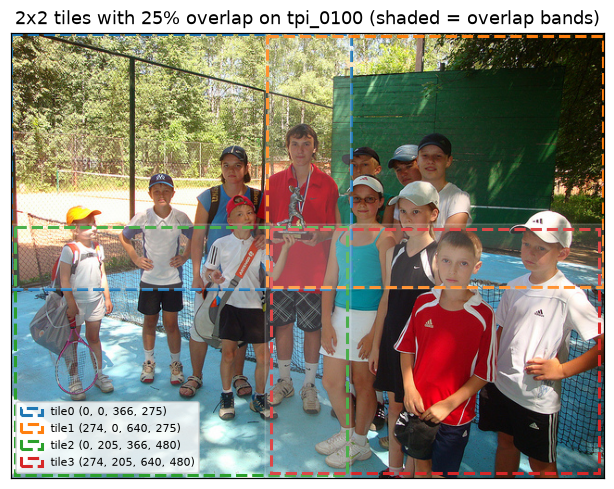

In [10]:
n_small = {k: sum(b == "small" for b in GT_BUCKET[k]) for k in CAL_KEYS}
DEMO = max(CAL_KEYS, key=lambda k: (n_small[k], k))
W, H = SIZES[DEMO]
tiles = pdet.tile_grid(W, H)
tw, th = tiles[0][2], tiles[0][3]
print(f"{DEMO}: {W}x{H} px | tile {tw}x{th} px | overlap band {2 * tw - W} px horizontally "
      f"({(2 * tw - W) / tw:.1%} of the tile width), {2 * th - H} px vertically ({(2 * th - H) / th:.1%}) | "
      f"inner-edge margin {pdet.TILE_EDGE_MARGIN:.0f} px | small GT instances: {n_small[DEMO]}")
fig, ax = plt.subplots(figsize=(7, 7 * H / W))
ax.imshow(Image.open(PATHS.dev_images_dir / f"{DEMO}.jpg"))
for i, (x1, y1, x2, y2) in enumerate(tiles):
    ax.add_patch(mpatches.Rectangle((x1 + 2 * i, y1 + 2 * i), x2 - x1 - 4 * i, y2 - y1 - 4 * i, fill=False,
                                    lw=2, ls="--", ec=f"C{i}", label=f"tile{i} {tiles[i]}"))
ax.axvspan(tiles[1][0], tiles[0][2], color="white", alpha=0.15)
ax.axhspan(tiles[2][1], tiles[0][3], color="white", alpha=0.15)
ax.set(title=f"2x2 tiles with 25% overlap on {DEMO} (shaded = overlap bands)", xticks=[], yticks=[])
ax.grid(False)
ax.legend(loc="lower left", fontsize=7)
plt.show()

**Analysis — tile geometry.**

- **Tile size and overlap.**
  - For a 640×480 image (`tpi_0100`, the CAL image with the most small GT instances: 43), `tile_grid` yields four 366×275 windows.
  - The shared bands are 92 px horizontally and 70 px vertically: 25.1% and 25.5% of the tile side. *25% overlap* is defined relative to the tile, hence `tile = dim / 1.75`.
- **Coverage guarantee (unit-tested).**
  - Any object narrower than the horizontal band and shorter than the vertical band (minus the 3-px margin, i.e. up to ~85 × 63 px here) lies entirely inside at least one tile **without touching that tile's inner border**.
  - This is what makes the truncation filter safe. Every box that touches an inner border is either a partial view of an object that another tile (or the global view) sees whole, or an object too large for tiling to matter.
- **Inner vs. image borders.** Only *inner* borders count as truncation. A tile border that coincides with the image border is the photo's own crop, and objects cut there are cut in the global view too, so filtering them would only lose recall.
- **Projection.** Tile boxes are translated by the tile origin, clipped to `[0, W] × [0, H]`, and tagged `owlv2:tile{i}`, so every merged detection keeps its view of origin for later traceability and calibration.

In [11]:
by_cat = defaultdict(list)
for k in CAL_KEYS:
    for cid, ar in zip(GT[k]["categories"], AREA_RATIO[k]):
        by_cat[cid].append(ar)
TILE_CATEGORIES = sorted(c for c in cfg.CATEGORIES
                         if c not in by_cat or np.median(by_cat[c]) < cfg.MEDIUM_MAX_AREA_RATIO)
excluded = sorted((c for c in cfg.CATEGORIES if c not in TILE_CATEGORIES), key=lambda c: -np.median(by_cat[c]))
display(pd.DataFrame([{"category": cfg.CATEGORIES[c], "CAL GT": len(by_cat[c]),
                       "median area_ratio": float(np.median(by_cat[c]))} for c in excluded]).round(4))
print(f"tiled categories: {len(TILE_CATEGORIES)}/120 (CAL GT median area_ratio < {cfg.MEDIUM_MAX_AREA_RATIO}; "
      f"{sum(c not in by_cat for c in cfg.CATEGORIES)} absent from CAL, included) | excluded (large): {len(excluded)}")
TILING_PATH = CACHE_DIR / "tiling_categories.json"
TILING_PATH.write_text(json.dumps({
    "rule": f"CAL GT median area_ratio < {cfg.MEDIUM_MAX_AREA_RATIO} (categories absent from CAL included)",
    "split": "CAL", "category_ids": TILE_CATEGORIES,
    "excluded": {cfg.CATEGORIES[c]: round(float(np.median(by_cat[c])), 5) for c in excluded}}, indent=2),
    encoding="utf-8")
print(f"wrote {TILING_PATH.relative_to(REPO)}")

,category,CAL GT,median area_ratio
0,bus,2,0.2187
1,bed,6,0.1875
2,train,3,0.1452
3,horse,1,0.1373
4,blanket,10,0.0859
5,motorcycle,3,0.0776
6,curtain,5,0.0658
7,surfboard,2,0.0652
8,cat,5,0.0644
9,sofa,9,0.0590


tiled categories: 106/120 (CAL GT median area_ratio < 0.035; 1 absent from CAL, included) | excluded (large): 14
wrote artifacts/cache_exp02/tiling_categories.json


**Analysis — which categories are tiled.**

- **Rule.**
  - A category is tiled when its **CAL** GT median `area_ratio` is below the medium/large boundary (0.035). Categories absent from CAL are included by default.
  - This is a training-side hyperparameter, exactly like the CAL score threshold: it is fixed once for the whole dataset, never chosen per image and never from the image being predicted, so it does not leak ground truth into inference. It is frozen in `artifacts/cache_exp02/tiling_categories.json` for T4.
- **Result.** 106 of 120 categories are tiled. The 14 excluded ones are the obvious large-scale classes (`bus`, `bed`, `train`, `horse`, `blanket`, `motorcycle`, `curtain`, `surfboard`, `cat`, `sofa`, `toilet`, `refrigerator`, `computer monitor`) **and `person`** (median 0.042).
- **Why excluding `person` matters.** A person seen through a tile is a partial body (torso, legs) that OWLv2 happily labels `person`. These partial boxes do not match the full-body GT and, since `person` is almost always an exhaustive positive, every one of them is a federated false positive. The next table shows this effect.

In [12]:
ALL_CATEGORIES = set(cfg.CATEGORIES)


def tiled(dets_by_key, global_thr, tile_thr, categories, gate, drop_truncated=True):
    """Global view at its own threshold + tile views at theirs, merged by merge_views (filter, gate, NMS)."""
    return {k: pdet.merge_views([d for d in dets_by_key[k] if not is_global(d) or d.score >= global_thr],
                                *SIZES[k], set(categories), drop_truncated=drop_truncated, tile_min_score=tile_thr,
                                tile_max_area_ratio=cfg.MEDIUM_MAX_AREA_RATIO if gate else None)
            for k in CAL_KEYS}


def best_of(make, thresholds):
    sw = sweep(make, thresholds)
    return float(sw.loc[sw["F1"].idxmax(), "threshold"])


D = DETS[WIN_KEY]
G = global_only(D)
ARMS = {}
ARMS["B0 full image"] = (WIN_T, None, at_threshold(G, WIN_T))
t = best_of(lambda t: tiled(D, t, t, ALL_CATEGORIES, False, drop_truncated=False), THRESHOLDS)
ARMS["B1 + tiles, one shared threshold, no truncation filter"] = (t, t, tiled(D, t, t, ALL_CATEGORIES, False, False))
t = best_of(lambda t: tiled(D, t, t, ALL_CATEGORIES, False), THRESHOLDS)
ARMS["B2 + tiles, one shared threshold, truncation filter"] = (t, t, tiled(D, t, t, ALL_CATEGORIES, False))
t = best_of(lambda t: tiled(D, WIN_T, t, ALL_CATEGORIES, False), TILE_THRESHOLDS)
ARMS["B3 + tiles, per-view thresholds, truncation filter"] = (WIN_T, t, tiled(D, WIN_T, t, ALL_CATEGORIES, False))
t = best_of(lambda t: tiled(D, WIN_T, t, ALL_CATEGORIES, True), TILE_THRESHOLDS)
ARMS["B4 + size gate (all 120 categories tiled)"] = (WIN_T, t, tiled(D, WIN_T, t, ALL_CATEGORIES, True))
TILE_T = best_of(lambda t: tiled(D, WIN_T, t, TILE_CATEGORIES, True), TILE_THRESHOLDS)
ARMS["B5 selective tiling: + small/medium category subset"] = (WIN_T, TILE_T, tiled(D, WIN_T, TILE_T, TILE_CATEGORIES, True))

EXP02B = pd.DataFrame([summarize(dets, name, **{"global thr": gt, "tile thr": tt}) for name, (gt, tt, dets) in ARMS.items()])
display(EXP02B[["arm", "global thr", "tile thr", "P", "R", "F1", "R_small", "R_medium", "R_large", "det/img"]].round(4))

tiles_in = [d for k in CAL_KEYS for d in D[k] if not is_global(d) and d.score >= TILE_T and d.category_id in TILE_CATEGORIES]
cut = sum(pdet.touches_inner_edge(d.bbox, pdet.tile_grid(*SIZES[k])[pdet.view_index(d.source)], *SIZES[k])
          for k in CAL_KEYS for d in D[k]
          if not is_global(d) and d.score >= TILE_T and d.category_id in TILE_CATEGORIES)
print(f"tile detections >= {TILE_T} in the tiled subset: {len(tiles_in)} | removed as inner-edge truncation "
      f"artifacts: {cut} ({cut / len(tiles_in):.1%})")

,arm,global thr,tile thr,P,R,F1,R_small,R_medium,R_large,det/img
0,B0 full image,0.175,NaN,0.6850,0.6361,0.6596,0.5211,0.7454,0.8000,34.0500
1,"B1 + tiles, one shared threshold, no truncation filter",0.250,0.250,0.5953,0.6190,0.6069,0.5352,0.7106,0.7062,35.3375
2,"B2 + tiles, one shared threshold, truncation filter",0.225,0.225,0.6839,0.6434,0.6630,0.5665,0.7292,0.7188,34.7125
3,"B3 + tiles, per-view thresholds, truncation filter",0.175,0.275,0.6661,0.6629,0.6645,0.5665,0.7523,0.8062,37.1500
4,B4 + size gate (all 120 categories tiled),0.175,0.275,0.6683,0.6629,0.6656,0.5665,0.7546,0.8000,36.9875
5,B5 selective tiling: + small/medium category subset,0.175,0.250,0.6598,0.6742,0.6669,0.5853,0.7593,0.8000,38.6875


tile detections >= 0.25 in the tiled subset: 2968 | removed as inner-edge truncation artifacts: 826 (27.8%)


**Analysis — the incremental tiling ablation (CAL, Base `chunked_raw`).**

- **B1, naive tiling, is harmful: F1 0.660 → 0.607.**
  - Without the truncation filter, every object crossing an inner border produces partial boxes; precision collapses 0.685 → 0.595.
  - The filter removes **27.8%** of all tile detections above the final tile threshold (826 of 2,968). Truncation artifacts are not an edge case; they are a quarter of what tiling produces.
- **B2, filter only, still hides a trap.**
  - F1 recovers to 0.663 and small recall climbs to 0.567, but **large recall falls 0.800 → 0.719**.
  - With a single threshold shared by all views, the optimum moves from 0.175 to 0.225 to absorb the extra tile false positives. Global detections of large objects scoring 0.175–0.225 are lost, even though tiling never touched them.
  - The tile views and the global view have **different score scales** (the zoomed-in view is more confident on small things and noisier overall), and one threshold cannot serve both.
- **B3, per-view thresholds, fixes it.**
  - The global view stays at 0.175 and tiles get their own threshold (0.275).
  - Large recall returns to 0.806, recall rises to 0.663 and F1 to 0.6645.
- **B4, size gate:** a small precision gain (0.666 → 0.668) for the same recall. Tiles stop contributing large boxes, which they could only produce as partial views anyway.
- **B5, category subset, gives the best arm.**
  - Excluding the 14 large categories (`person` in particular) removes a major source of tile false positives. The CAL-optimal tile threshold can then drop to 0.25, which lifts small recall to **0.585** and medium recall to 0.759.
  - Final CAL Box F1 0.6669, recall 0.674 (+3.8 pp over B0), precision 0.660 (−2.5 pp).
- **Reading.** Each ingredient is necessary. The naive version of the technique (B1) is *worse than not tiling at all*, which is why the truncation filter and per-view thresholds are part of the method and not optional refinements.

,comparison,metric,delta,ci_low,ci_high,p(delta<=0),significant (95% CI excludes 0)
0,B5 selective tiling - B0 full image,P,-0.0253,-0.0381,-0.0140,1.000,True
1,B5 selective tiling - B0 full image,R,0.0382,0.0274,0.0488,0.000,True
2,B5 selective tiling - B0 full image,F1,0.0073,-0.0030,0.0177,0.090,False
3,B5 selective tiling - B0 full image,R_small,0.0642,0.0457,0.0820,0.000,True
4,B5 selective tiling - B0 full image,R_medium,0.0139,0.0021,0.0272,0.019,True
5,B5 selective tiling - B0 full image,R_large,0.0000,0.0000,0.0000,1.000,False
6,B5 (EXP-02A+B) - EXP-01 baseline,P,-0.0285,-0.0414,-0.0164,1.000,True
7,B5 (EXP-02A+B) - EXP-01 baseline,R,0.0447,0.0323,0.0581,0.000,True
8,B5 (EXP-02A+B) - EXP-01 baseline,F1,0.0093,-0.0024,0.0210,0.060,False
9,B5 (EXP-02A+B) - EXP-01 baseline,R_small,0.0689,0.0512,0.0865,0.000,True


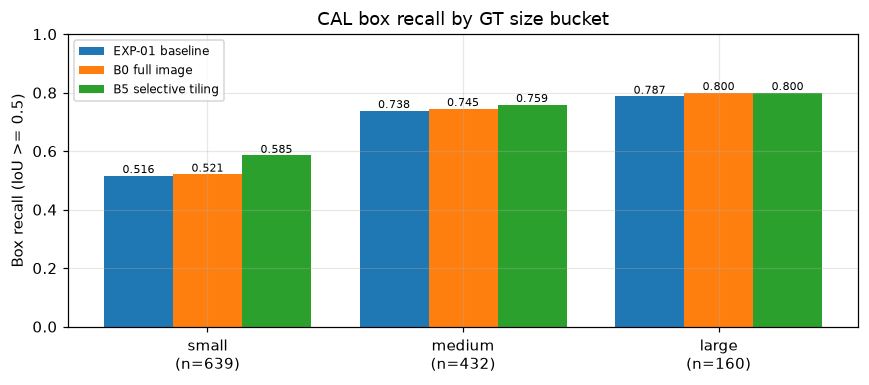

S3 check vs EXP-01 on CAL: delta R_small = +0.0689 [+0.0512, +0.0865], delta Box F1 = +0.0093 [-0.0024, +0.0210]


In [13]:
COUNTS_B = {name: per_image_counts(dets) for name, (_, _, dets) in ARMS.items()}
COUNTS_EXP01 = per_image_counts(at_threshold({k: EXP01[k] for k in CAL_KEYS}, 0.175))
FINAL = "B5 selective tiling: + small/medium category subset"
rows = []
for label, a, b in (("B5 selective tiling - B0 full image", COUNTS_B["B0 full image"], COUNTS_B[FINAL]),
                    ("B5 (EXP-02A+B) - EXP-01 baseline", COUNTS_EXP01, COUNTS_B[FINAL]),
                    ("B2 shared threshold - B0 full image", COUNTS_B["B0 full image"],
                     COUNTS_B["B2 + tiles, one shared threshold, truncation filter"])):
    boot = bootstrap_delta(a, b)
    rows += [{"comparison": label, "metric": m, **boot[m]} for m in METRICS]
BOOT_B = pd.DataFrame(rows)
BOOT_B["significant (95% CI excludes 0)"] = (BOOT_B["ci_low"] > 0) | (BOOT_B["ci_high"] < 0)
display(BOOT_B.round(4))

fig, ax = plt.subplots(figsize=(8, 3.6))
arms = [("EXP-01 baseline", COUNTS_EXP01), ("B0 full image", COUNTS_B["B0 full image"]), ("B5 selective tiling", COUNTS_B[FINAL])]
for i, (name, counts) in enumerate(arms):
    m = metrics_from_sums(counts.sum(axis=0))
    vals = [float(m[f"R_{b}"]) for b in BUCKETS]
    bars = ax.bar(np.arange(3) + (i - 1) * 0.27, vals, width=0.27, label=name)
    ax.bar_label(bars, fmt="%.3f", fontsize=7)
ax.set_xticks(range(3), [f"{b}\n(n={n_bucket[b]})" for b in BUCKETS])
ax.set(ylabel="Box recall (IoU >= 0.5)", ylim=(0, 1), title="CAL box recall by GT size bucket")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
s3 = BOOT_B[BOOT_B["comparison"] == "B5 (EXP-02A+B) - EXP-01 baseline"].set_index("metric")
print("S3 check vs EXP-01 on CAL:",
      f"delta R_small = {s3.loc['R_small', 'delta']:+.4f} [{s3.loc['R_small', 'ci_low']:+.4f}, {s3.loc['R_small', 'ci_high']:+.4f}],",
      f"delta Box F1 = {s3.loc['F1', 'delta']:+.4f} [{s3.loc['F1', 'ci_low']:+.4f}, {s3.loc['F1', 'ci_high']:+.4f}]")

**Analysis — statistical significance and the S3 verdict.**

- **B5 vs. B0 (the effect of selective tiling alone).**
  - Recall +3.8 pp, CI [+2.7, +4.9].
  - **Small recall +6.4 pp, CI [+4.6, +8.2].**
  - Medium recall +1.4 pp, CI [+0.2, +2.7].
  - Large recall exactly unchanged: by construction, the size gate and the fixed global threshold make tiling unable to touch large objects.
  - These gains are paid for with precision −2.5 pp, CI [−3.8, −1.4]. Net Box F1 **+0.0073, CI [−0.0030, +0.0177], p(Δ ≤ 0) = 0.09: not significant.**
- **B5 vs. EXP-01 (the full EXP-02A+B system against the baseline; this is the S3 criterion).**
  - **Small-object recall (`area_ratio < 0.0035`): 0.516 → 0.585, +6.9 pp, CI [+5.1, +8.7], p < 0.001: significant ✔.**
  - Medium recall +2.1 pp (significant). Large +1.2 pp (not significant).
  - **Global Box F1: 0.6576 → 0.6669, +0.0093, CI [−0.0024, +0.0210], p(Δ ≤ 0) = 0.06: positive, but *not* significant at 95% ✘.**
- **S3 verdict: partially met.**
  - The small-object recall criterion is clearly met.
  - The global Box F1 criterion is met in direction, but its 95% CI includes 0 on 80 CAL images.
  - Both numbers are in-sample (thresholds tuned on CAL), so the true effect is if anything smaller. The held-out confirmation is T4's VAL comparison.
- **Why F1 lags behind recall.**
  - Under the federated LVIS policy every extra tile detection of a verified-negative or exhaustive-positive category is a false positive. Tiles find small objects, but they also find small *non-objects*, and they are not corroborated by the global view.
  - With independent per-view scores and NMS-only merging, the recall gain is largely cancelled by precision. That points at T4's tools: score calibration per view/detector and fusion (WBF / cross-view consensus), so that a box seen in two views is promoted and an isolated tile box is demoted.
- **B2 vs. B0 is the cautionary control.** The shared-threshold implementation *significantly loses* 8.1 pp of large recall (CI [−13.1, −3.4]) for no significant F1 gain. A naive tiling implementation would have reported a misleading "small-object win" while silently degrading large objects.

In [14]:
rows = []
for bb in BACKBONES:
    for v in pdet.VARIANTS:
        Dv, gt_thr = DETS[bb, v], BEST_T[bb, v]
        base_row = summarize(at_threshold(global_only(Dv), gt_thr), "")
        tt = best_of(lambda t: tiled(Dv, gt_thr, t, TILE_CATEGORIES, True), TILE_THRESHOLDS)
        tile_row = summarize(tiled(Dv, gt_thr, tt, TILE_CATEGORIES, True), "")
        rows.append({"arm": f"{bb} / {v}", "global thr": gt_thr, "tile thr": tt, "F1 full": base_row["F1"],
                     "F1 +tiles": tile_row["F1"], "delta F1": tile_row["F1"] - base_row["F1"],
                     "R_small full": base_row["R_small"], "R_small +tiles": tile_row["R_small"],
                     "delta R_small": tile_row["R_small"] - base_row["R_small"],
                     "delta R_large": tile_row["R_large"] - base_row["R_large"]})
ROBUST = pd.DataFrame(rows)
display(ROBUST.round(4))

,arm,global thr,tile thr,F1 full,F1 +tiles,delta F1,R_small full,R_small +tiles,delta R_small,delta R_large
0,base / single_raw,0.175,0.250,0.6576,0.6661,0.0085,0.5164,0.5837,0.0673,0.0
1,base / single_alias,0.175,0.250,0.6538,0.6624,0.0086,0.5196,0.5853,0.0657,0.0
2,base / chunked_raw,0.175,0.250,0.6596,0.6669,0.0073,0.5211,0.5853,0.0642,0.0
3,base / chunked_alias,0.175,0.250,0.6536,0.6616,0.0080,0.5227,0.5869,0.0642,0.0
4,large / single_raw,0.175,0.225,0.6259,0.6315,0.0057,0.4757,0.5383,0.0626,0.0
5,large / single_alias,0.175,0.300,0.6247,0.6303,0.0056,0.4789,0.5070,0.0282,0.0
6,large / chunked_raw,0.175,0.225,0.6261,0.6318,0.0057,0.4773,0.5415,0.0642,0.0
7,large / chunked_alias,0.175,0.300,0.6245,0.6300,0.0055,0.4820,0.5102,0.0282,0.0


**Analysis — robustness of the tiling effect across all 8 EXP-02A arms.**

- **Same protocol everywhere.** The B5 protocol was applied unchanged to every backbone × prompting variant: global view at its own optimum, tile threshold tuned, same subset, gate and filter.
- **The tiling gain is robust.**
  - F1 rises in all 8 arms (+0.0055 to +0.0086).
  - Small recall rises in all 8 (+2.8 to +6.7 pp).
  - Large recall is untouched in all 8.
- **The effect size dwarfs the prompting effects.** Tiling adds 6–7 pp of small recall wherever it is applied; the best prompting change (chunking) added 0.5 pp. Resolution, not vocabulary, is what limits small-object detection.
- **Weaker cases.** The gain is smallest for Large with aliases (+2.8 pp small recall, tile threshold 0.30): the extra alias false positives in the tile views force a stricter tile threshold. This is consistent with Section 1: aliases cost precision, and the cost compounds over 4 extra views.
- **Large stays behind Base after tiling** (F1 0.632 vs. 0.667). Tiling does not close the backbone gap.

In [15]:
rows = []
for bb in BACKBONES:
    sec = np.array([r["duration_ms"] for r in TRACE[bb]]) / 1000
    rows.append({"backbone": bb, "GPU": META[bb, "single_raw"]["gpu"], "images": len(sec),
                 "mean s/img (5 views)": sec.mean(), "p95 s/img": np.percentile(sec, 95),
                 "approx. s/view": sec.mean() / 5, "peak VRAM MB": max(r["vram_peak_mb"] for r in TRACE[bb]),
                 "raw global det/img (chunked_alias)": np.mean([sum(is_global(d) for d in DETS[bb, "chunked_alias"][k]) for k in DETS[bb, "chunked_alias"]]),
                 "raw tile det/img (chunked_alias)": np.mean([sum(not is_global(d) for d in DETS[bb, "chunked_alias"][k]) for k in DETS[bb, "chunked_alias"]])})
display(pd.DataFrame(rows).round(2))

,backbone,GPU,images,mean s/img (5 views),p95 s/img,approx. s/view,peak VRAM MB,raw global det/img (chunked_alias),raw tile det/img (chunked_alias)
0,base,Tesla T4,180,2.65,2.79,0.53,780.45,179.03,335.15
1,large,Tesla T4,180,11.41,11.64,2.28,2017.66,133.11,309.23


**Analysis — computational cost (Kaggle Tesla T4, FP32).**

- **Base.**
  - 2.65 s per image for the 5 views (≈ 0.53 s per view), p95 2.79 s.
  - Peak VRAM 780 MB.
  - The timing includes preprocessing, the 183-query forward and the NumPy extraction of 4 variants with per-class NMS.
- **Large.**
  - 11.4 s per image (≈ 2.3 s per view): 4.3× Base, consistent with a ViT-L/14 at 1008 px vs. a ViT-B/16 at 960 px.
  - Peak VRAM 2.0 GB. Both are far below the 14 GB budget of suite Test 8.
- **Where the cost comes from.**
  - Chunking and aliases are **free** with OWLv2: one forward pass, 183 instead of 120 short text queries.
  - Tiling multiplies the detection cost by **5×** (1 global + 4 tiles).
  - For the 60 test images, Base + tiling costs ~2.7 minutes on a T4, which is acceptable for the submission. Large + tiling (~11 minutes) is hard to justify given that it is the worse detector.
- **Cache size.** Tile views produce ~1.9× as many raw candidates as the global view (335 vs. 179 per image for Base `chunked_alias` at the 0.05 floor). Compressed, all 4 variants × 5 views for 180 images fit in ~7 MB per backbone.

GT instances rescued by tiling: 50 {'small': 42, 'medium': 8} | lost: 3 {'small': 1, 'medium': 2}
most rescued categories: knife (5), earring (3), pillow (3), book (2), awning (2), napkin (2), license plate (2), sock (2), flowerpot (2), taillight (2), laptop (1), basket (1)
tpi_0115: rescued knife (area_ratio 0.00019), knife (area_ratio 0.00018), knife (area_ratio 0.00022), knife (area_ratio 0.00031), knife (area_ratio 0.00024)


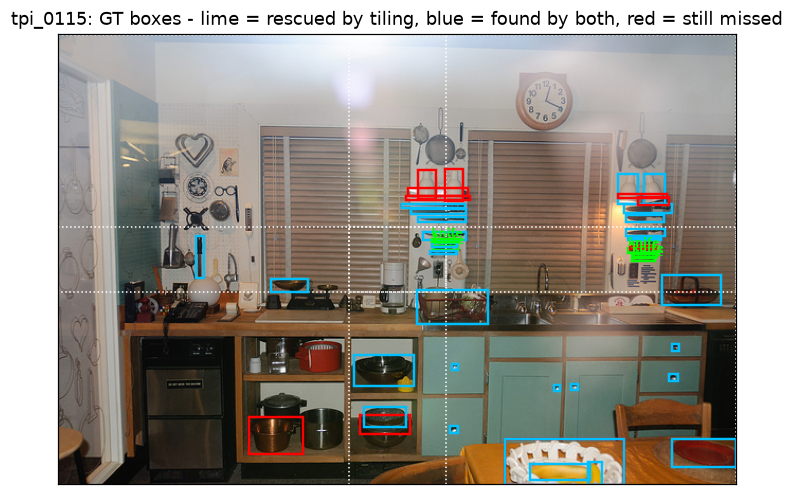

In [16]:
b0 = ev.box_match_details({k: as_preds(ARMS["B0 full image"][2][k]) for k in CAL_KEYS}, GT)
b5 = ev.box_match_details({k: as_preds(ARMS[FINAL][2][k]) for k in CAL_KEYS}, GT)
rescued = {k: [i for i, (a, b) in enumerate(zip(b0[k]["gt_matched"], b5[k]["gt_matched"])) if b and not a] for k in CAL_KEYS}
lost = {k: [i for i, (a, b) in enumerate(zip(b0[k]["gt_matched"], b5[k]["gt_matched"])) if a and not b] for k in CAL_KEYS}
by_size = Counter(GT_BUCKET[k][i] for k in CAL_KEYS for i in rescued[k])
by_size_lost = Counter(GT_BUCKET[k][i] for k in CAL_KEYS for i in lost[k])
print(f"GT instances rescued by tiling: {sum(map(len, rescued.values()))} {dict(by_size)} | "
      f"lost: {sum(map(len, lost.values()))} {dict(by_size_lost)}")
top = Counter(cfg.CATEGORIES[GT[k]['categories'][i]] for k in CAL_KEYS for i in rescued[k]).most_common(12)
print("most rescued categories:", ", ".join(f"{n} ({c})" for n, c in top))

QUAL = max(CAL_KEYS, key=lambda k: (len(rescued[k]), k))
W, H = SIZES[QUAL]
print(f"{QUAL}: rescued " + ", ".join(
    f"{cfg.CATEGORIES[GT[QUAL]['categories'][i]]} (area_ratio {AREA_RATIO[QUAL][i]:.5f})" for i in rescued[QUAL]))
fig, ax = plt.subplots(figsize=(8, 8 * H / W))
ax.imshow(Image.open(PATHS.dev_images_dir / f"{QUAL}.jpg"))
for (x1, y1, x2, y2) in pdet.tile_grid(W, H):
    ax.add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1, ls=":", ec="white"))
for i, (box, cid, hit) in enumerate(zip(GT[QUAL]["boxes"], GT[QUAL]["categories"], b5[QUAL]["gt_matched"])):
    color = "lime" if i in rescued[QUAL] else ("deepskyblue" if hit else "red")
    ax.add_patch(mpatches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1], fill=False, lw=1.6, ec=color))
    if i in rescued[QUAL]:
        ax.text(box[0], box[1] - 2, cfg.CATEGORIES[cid], color="lime", fontsize=7, weight="bold")
ax.set(title=f"{QUAL}: GT boxes - lime = rescued by tiling, blue = found by both, red = still missed", xticks=[], yticks=[])
ax.grid(False)
plt.show()

**Analysis — what tiling rescues.**

- **Overall.**
  - Across CAL, the final configuration matches **50 GT instances** that the full-image view missed (42 small, 8 medium) and loses only 3 (1 small, 2 medium).
  - A rescue/loss ratio of ~17:1 is the per-instance picture behind the +6.4 pp small recall.
- **The 3 losses.** A higher-scoring tile box of the same class wins per-class NMS over a better-localised global box, then falls below IoU 0.5 with the GT. Cross-view WBF (T4) would average the two boxes instead of picking one.
- **Rescued categories are the micro-objects that motivated the experiment:** `knife` (5), `earring` (3), `pillow` (3), `book`, `awning`, `napkin`, `license plate`, `sock`, `flowerpot`, `taillight` (2 each).
- **Showcase image `tpi_0115` (a kitchen).**
  - All 5 rescues are knives hanging on wall racks, each with `area_ratio` 0.00018–0.00031 (≈ 55–95 px² in a 640×480 image).
  - At the global resolution each knife spans about one OWLv2 patch; in the tile it spans several.
  - The objects still missed (red) are partly occluded pots and utensils clustered at the top of the racks. Higher resolution alone does not separate touching instances; that requires better localisation or a different detector family.

In [17]:
final = EXP02B.set_index("arm").loc[FINAL]
SUMMARY = {
    "exp02a_selection": {"rule": "max CAL Box F1 over 8 global arms", "backbone": WIN_KEY[0], "variant": WIN_KEY[1],
                         "global_threshold": WIN_T},
    "exp02b_selective_tiling": {"global_threshold": WIN_T, "tile_threshold": TILE_T,
                                "tile_max_area_ratio": cfg.MEDIUM_MAX_AREA_RATIO,
                                "tile_categories": str(TILING_PATH.relative_to(REPO)),
                                "truncation_filter_margin_px": pdet.TILE_EDGE_MARGIN, "overlap": pdet.TILE_OVERLAP},
    "cal_metrics": {k: round(float(final[k]), 4) for k in METRICS},
    "s3_vs_exp01": {m: {k: round(float(s3.loc[m, k]), 4) for k in ("delta", "ci_low", "ci_high")} for m in ("F1", "R_small")},
    "thresholds_selected_on": "CAL (in-sample); VAL held out for T4 Section 3",
}
SUMMARY_PATH = CACHE_DIR / "exp02ab_summary.json"
SUMMARY_PATH.write_text(json.dumps(SUMMARY, indent=2), encoding="utf-8")
print(json.dumps(SUMMARY, indent=2))

{
  "exp02a_selection": {
    "rule": "max CAL Box F1 over 8 global arms",
    "backbone": "base",
    "variant": "chunked_raw",
    "global_threshold": 0.175
  },
  "exp02b_selective_tiling": {
    "global_threshold": 0.175,
    "tile_threshold": 0.25,
    "tile_max_area_ratio": 0.035,
    "tile_categories": "artifacts/cache_exp02/tiling_categories.json",
    "truncation_filter_margin_px": 3.0,
    "overlap": 0.25
  },
  "cal_metrics": {
    "P": 0.6598,
    "R": 0.6742,
    "F1": 0.6669,
    "R_small": 0.5853,
    "R_medium": 0.7593,
    "R_large": 0.8
  },
  "s3_vs_exp01": {
    "F1": {
      "delta": 0.0093,
      "ci_low": -0.0024,
      "ci_high": 0.021
    },
    "R_small": {
      "delta": 0.0689,
      "ci_low": 0.0512,
      "ci_high": 0.0865
    }
  },
  "thresholds_selected_on": "CAL (in-sample); VAL held out for T4 Section 3"
}


## Conclusions of EXP-02A/B and hand-off to T4

| question | answer (CAL, 80 images, 95% paired bootstrap) |
|---|---|
| Does chunked prompting (5 × 24) help OWLv2? | Recall +0.65 pp (significant), F1 +0.002 (n.s.). Free at inference. **Kept.** |
| Do LVIS visual aliases help OWLv2? | Precision −1.2 to −1.8 pp (significant), recall n.s. **Dropped by default.** |
| Is the explicit sibling rule needed? | 0 suppressions at the operating point; the per-block argmax already disambiguates. Kept as a free guard. |
| Does selective 2×2 tiling help small objects? | **Small recall +6.4 pp [+4.6, +8.2]**, medium +1.4 pp, large unchanged; F1 +0.007 (n.s.). **Kept.** |
| S3 vs. EXP-01 | **Small recall +6.9 pp [+5.1, +8.7] ✔**; Box F1 +0.0093 [−0.0024, +0.0210] ✘ (positive, not significant at 95%). **Partially met.** |

**Final EXP-02A/B configuration.**
- Detector and prompting: OWLv2 Base, `chunked_raw`, global threshold 0.175.
- Tiling: 2×2 tiles with 25% overlap, tile threshold 0.25, inner-edge truncation filter (3 px), size gate `area_ratio < 0.035`, 106 tiled categories.
- CAL result: P 0.660, R 0.674, F1 0.6669, small recall 0.585.
- Frozen in `artifacts/cache_exp02/exp02ab_summary.json` and `tiling_categories.json`.

**Findings T4 must act on.**
1. **OWLv2 Large is significantly worse than OWLv2 Base on this data** (F1 −0.032, CI [−0.056, −0.008]) and 4.3× slower. The master plan's ensemble assumes Large is the strong OWLv2 member; T4 should treat Base and Large as candidates and decide on CAL/VAL, not by model size.
2. **Precision, not recall, is now the bottleneck.** Tiling's recall gain is cancelled by uncorroborated tile false positives. This is exactly what per-view/per-detector score calibration and WBF fusion (a box confirmed by two views or two detectors is promoted) are designed to solve, and the most likely way to turn the recall gain into a significant F1 gain.
3. **Views have different score scales.** A single threshold across views costs −8.1 pp of large recall (B2). Calibration in T4 must be per detector *and* per view (global vs. tile).
4. **Chunking matters for MM-GDINO for a different reason.** Its BERT encoder truncates at 256 tokens, and the 120 classes do not fit in one prompt. For GDINO the 5 × 24 blocks are a hard requirement, not an optimisation. Aliases may also help there more than with CLIP and deserve a re-test.
5. **Candidate sibling pair** `computer monitor` / `television set`, exposed by the `tv`/`television` aliases.
6. **Caches for T4.** `artifacts/cache_exp02/{base,large}/detections_{variant}.json.gz` cover all 180 images (CAL + VAL + test) with untouched tile views. The VAL comparison and the bootstrap CIs on VAL (T4 Section 3) need no new OWLv2 inference.